### SVR regression, housing data test with the TransformedTargetRegressor

**Trying GridSearchCV here too to find more optimal parameters.**

In [1]:
# usual imports in a classic ML pipeline for Regression
# pip install numpy
# pip install pandas
# pip install seaborn
# pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# import pipelines, SVM etc.
from sklearn.model_selection import train_test_split
from sklearn import metrics, svm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# this helps us with all the scaling, both X and y are scaled
# automatically!
from sklearn.compose import TransformedTargetRegressor

In [2]:
# load the data
df = pd.read_csv("Housing.csv")

# let's quickly see the first 5 rows of data
df.head(10)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


### STEP 2: Handle missing/duplicate values and HANDLE ALL CATEGORICAL VARIABLES CORRECTLY

**Case 1: Binary variables (only two options)**

If your dataset does not have any binary variables => remove/disable the code cell below.

In [3]:
# this just converts the value of column to 0 or 1
# factorize in pandas works too, but only one column at a time
from sklearn.preprocessing import LabelEncoder
variables = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
encoder = LabelEncoder()
df[variables] = df[variables].apply(encoder.fit_transform)

In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


**Case 2: Ordinal variables (categories that have an order/rank -> can be compared)**

In [5]:
# we don't have ordinal categories here, so we'll skip these, check the diamonds example later for this

**Case 3: Nominal categories (categories that can't be compared numerically)**

In [6]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['furnishingstatus']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [7]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0,0


In [8]:
# see the materials (Rovaniemi/Oulu/Helsinki), we can make a small optimization
# => remove the last new boolean variable, since it's going to be represented
# by a straight line of zeroes
df = df.drop("furnishingstatus_unfurnished", axis=1)

In [9]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,1,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,0,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,1,0


### STEP 3: Data is good to go (all numbers) => train model etc.

In [10]:
# first step, we split our data into SUPPORT variables and the TARGET variable
# X => support variables, y => target variable

# X => list of support variables the model uses 
# while predicting the target variable with the model
X = df.drop("price", axis=1)

# our target variable is y
y = df['price']

**IMPORTANT WHEN OPTIMIZING PARAMETERS!**

Always lock down randomness in your algorithm and data so that your baseline remains the same. If you don't do this, you never know if the model improved because of the parameters or just sheer luck!

Here we only lock down train/test-split. We usually also lock down NumPy random seed + others!

In [11]:
# secondly, train/test -split with scikit-learn's helper function
# 0.3 for testing => 30% of data is reserved for testing purposes
# and based on that => it's deduced that 70% will be in the training data

# you can also define the random state, which is sometimes useful
# if you want to "lock down" all the randomness in order to get same results every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1718951)

**Finding optimal SVM parameters -> GridSearchCV**

**NOTE: poly-kernel is super heavy to train via GridSearchCV, rbf and linear are more light-weight!**

**Idea to improve this:** use a Pipeline also here in the GridSearchCV in order to have the same situation here as in the actual model training.

In [12]:
from sklearn.model_selection import GridSearchCV

# initialize testable parameters
# NOTE! all algorithms do not support all parameters
# see notes below which you can use with which
# # SVR() -> C, kernel, degree (if using poly), gamma, C, epsilon, max_iter
param_grid = {
    'C': [0.1, 0.25, 0.5, 1, 1.25, 1.5],
    'epsilon': [0.075, 0.1, 0.125],
    'gamma': [1, 0.25, 0.1, 0.05, 0.01], 
    'kernel': ['rbf']
}

# start finding the optimal parameters with GridSearchCV!
test_model = GridSearchCV(svm.SVR(), param_grid, verbose=3)
test_model.fit(X_train, y_train)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
[CV 1/5] END C=0.1, epsilon=0.075, gamma=1, kernel=rbf;, score=-0.018 total time=   0.0s
[CV 2/5] END C=0.1, epsilon=0.075, gamma=1, kernel=rbf;, score=-0.114 total time=   0.0s
[CV 3/5] END C=0.1, epsilon=0.075, gamma=1, kernel=rbf;, score=-0.115 total time=   0.0s
[CV 4/5] END C=0.1, epsilon=0.075, gamma=1, kernel=rbf;, score=-0.061 total time=   0.0s
[CV 5/5] END C=0.1, epsilon=0.075, gamma=1, kernel=rbf;, score=-0.097 total time=   0.0s
[CV 1/5] END C=0.1, epsilon=0.075, gamma=0.25, kernel=rbf;, score=-0.018 total time=   0.0s
[CV 2/5] END C=0.1, epsilon=0.075, gamma=0.25, kernel=rbf;, score=-0.114 total time=   0.0s
[CV 3/5] END C=0.1, epsilon=0.075, gamma=0.25, kernel=rbf;, score=-0.115 total time=   0.0s
[CV 4/5] END C=0.1, epsilon=0.075, gamma=0.25, kernel=rbf;, score=-0.061 total time=   0.0s
[CV 5/5] END C=0.1, epsilon=0.075, gamma=0.25, kernel=rbf;, score=-0.097 total time=   0.0s
[CV 1/5] END C=0.1, epsilon=0.075

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVR()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 0.25, ...], 'epsilon': [0.075, 0.1, ...], 'gamma': [1, 0.25, ...], 'kernel': ['rbf']}"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In a

In [13]:
test_model.best_params_

{'C': 1.5, 'epsilon': 0.125, 'gamma': 0.01, 'kernel': 'rbf'}

**We'll use Pipeline + TransformedTargetRegressor in order to scale both X and y -automatically**

In [14]:
# create the model and train it with the data
# use pipeline to scale the X-values automatically with StandardScaler
pipeline = make_pipeline(
    StandardScaler(), 
    svm.SVR(C=1.5, epsilon=0.125, gamma=0.01, kernel='rbf')
)

# use TransformedTargetRegressor to automatically scale y
# and pipelines above to automatically scale X
model = TransformedTargetRegressor(
    regressor=pipeline,
    transformer=MinMaxScaler()
)

# train the model
model.fit(X_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...gamma=0.01))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",MinMaxScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea','furnishingstatus_furnished', 'furnishingstatus_semi-furnished']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,13
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...gamma=0.01))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,MinMaxScaler,MinMaxScaler()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svr', ...)]"


In [15]:
# we need to create test predictions based on our earlier reserved test dataset
# this data has never been seen by the model by now
predictions = model.predict(X_test)

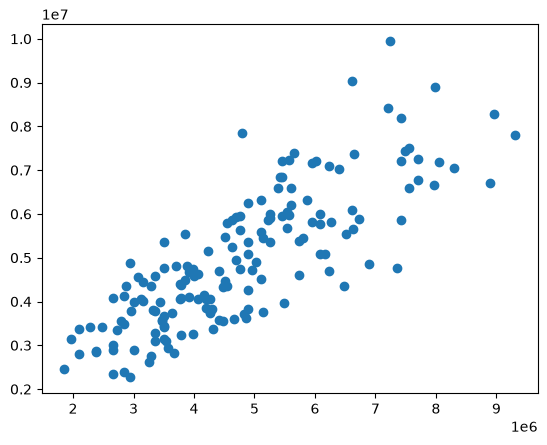

In [16]:
# let's plot how far the predictions are from the real target values (y)
# in the test dataset

# if the values follow a diagonal line (from bottom left to top right)
# => we have good predictions with the model
# we basically compare the predicted values to the actual true values 
# and compare the differences
plt.scatter(y_test, predictions)
plt.show()

In [17]:
# MAE = Mean average error
mae = metrics.mean_absolute_error(y_test, predictions)
print("MAE:")
print(f"{round(mae, 2)} $")

# MSE = Mean squared error
mse = metrics.mean_squared_error(y_test, predictions)
print("\nMSE:")
print(f"{round(mse, 2)} $^2")

# RMSE = Root Mean Squared Error
rmse = np.sqrt(mse)
print("\nRMSE:")
print(f"{round(rmse, 2)} $")

# R-square (or R2) - how well the model describes the original dataset
# 1 => model describes the data perfectly
# 0 => model doesn't describe the data at all
r2 = metrics.r2_score(y_test, predictions)
print("\nR-squared:")
print(f"{round(r2, 2)}")

# SCALED VERSIONS OF THE METRICS, only use MAE and RMSE
y_test_scaled = model.transformer_.transform(y_test.values.reshape(-1, 1)).ravel()
predictions_scaled = model.transformer_.transform(predictions.reshape(-1, 1)).ravel()

# calculate the scaled MAE and RMSE
mae_scaled = metrics.mean_absolute_error(y_test_scaled, predictions_scaled)
rmse_scaled = np.sqrt(metrics.mean_squared_error(y_test_scaled, predictions_scaled))

print(f"\nMAE scaled: {round(mae_scaled, 2)}")
print(f"\nRMSE scaled: {round(rmse_scaled, 2)}")


MAE:
805627.72 $

MSE:
979885020572.2 $^2

RMSE:
989891.42 $

R-squared:
0.61

MAE scaled: 0.07

RMSE scaled: 0.09


C:\Users\tuomas.valtanen\AppData\Local\Temp\ipykernel_20472\2920752686.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test - predictions))


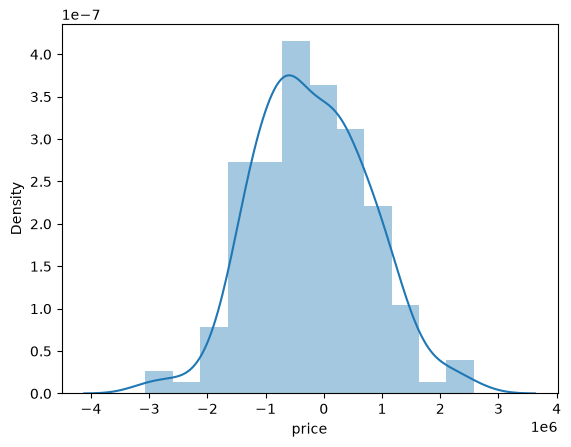

In [18]:
# if the prediction distribution is far from standard normal distritbuion
# then the model is not probably good enough
# distplot is deprecated and will be removed in future seaborn versions
# but not direct replacement has been created so far
sns.distplot((y_test - predictions))
plt.show()
plt.close()

In [19]:
X.columns

Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus_furnished', 'furnishingstatus_semi-furnished'],
      dtype='str')

In [20]:
# usually in GUI application we save the model-object / variable into a file (by using joblib-module)
# and in the GUI application => we load the saved model from the file
# and use the model just like here below

# map all the variables from the user
# into a Python dictionary
# the variable names have to match with the original dataset
tester_row = {
    'area': 3500, 
    'bedrooms': 3, 
    'bathrooms': 1, 
    'stories': 1, 
    'mainroad': 0, 
    'guestroom': 1,
    'basement': 1, 
    'hotwaterheating': 1, 
    'airconditioning': 1, 
    'parking': 5, 
    'prefarea': 0,
    'furnishingstatus_furnished': 0, 
    'furnishingstatus_semi-furnished': 0
}

# convert to pandas format
tester_row = pd.DataFrame([tester_row])

**No need to invert scaling here, Pipeline + TransformedTargetRegressor scale X/y -automatically!**

In [21]:
# get the output/result from the model
# based on the user's given new data (above code cell)
result = model.predict(tester_row)[0]

print()
print(f"Predicted price for this house:")
print(f"$ {round(float(result), 2)}")
print("----------------------------")


Predicted price for this house:
$ 6594032.29
----------------------------
